In [2]:
from pathlib import Path

TRAIN_PATH = Path('../data/raw/train_images/')
TEST_PATH = Path('../data/raw/test_images/')

In [10]:
import cv2
import matplotlib.pyplot as plt
from cv2.typing import MatLike


def load_image(path: Path) -> MatLike | None:
    # Using cv2 to load the image: it's the standard pattern for albumentations
    # since it works directly with RGB numpy arrays and therefore no PIL<->array
    # conversion is needed
    image = cv2.imread(str(path))
    if image is None:
        return None

    # But for historical reasons, CV2 loads images in BGR format. For
    # matplotlib's `imshow()`, they must be converted to RGB.
    image = cv2.cvtColor(src=image, code=cv2.COLOR_BGR2RGB)

    return image

def display_image(image: MatLike):
    print(image_path, image.shape, image.dtype)
    plt.imshow(image)
    plt.axis('off')
    plt.show()

..\data\raw\train_images\0011165.jpg (384, 576, 3) uint8


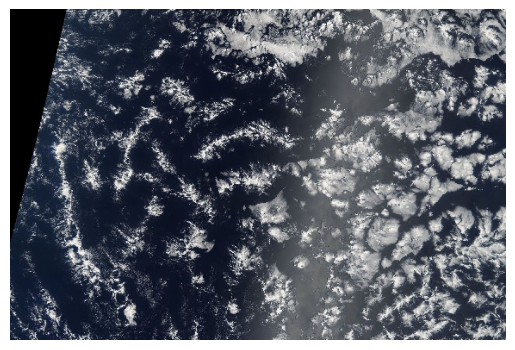

In [ ]:
# Load the 1st image from train path
image_path = sorted(TRAIN_PATH.iterdir())[0]
image = load_image(image_path)

# Display it
if image is not None:
    display_image(image)

**Note by `rosneru`:** Run the next cell multiple times to see other
Augmentation each time. This is because the randomness that is given to the
single transformations with the `p=` arguments.

Original shape: (384, 576, 3), Transformed shape: (384, 576, 3)
..\data\raw\train_images\0011165.jpg (384, 576, 3) uint8


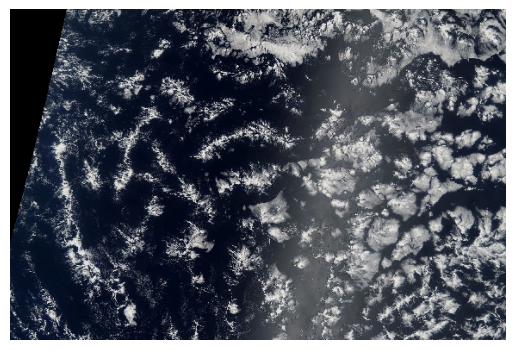

In [ ]:
import albumentations as A

image_mask_fish = None
image_mask_flower = None
image_mask_gravel = None
image_mask_sugar = None

if image is not None:
    pipeline = A.Compose([
        A.HorizontalFlip(p=0.3),
        A.VerticalFlip(p=0.3),
        A.RandomBrightnessContrast(p=0.8),
        A.Rotate(p=0.6)
    ])

    transformed_data = pipeline(image=image)
    transformed_image = transformed_data['image']

    print(f'Original shape: {image.shape}, '
          f'Transformed shape: {transformed_image.shape}')
    display_image(transformed_image)